# Part 1: Linear Regression

For this assignment, you will implement Linear Regression as learned in class. You will use both an analytical approach and a gradient descent approach for this assignment.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

In [3]:
# Load the diabetes dataset
data = load_diabetes()
X = data.data
y = data.target
print("features:", X.shape)
print("labels:", y.shape)

# TODO: Split the dataset into training and testing sets
# You may use train_test_split in sklearn
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2)
print("training data:", X_train.shape, y_train.shape)
print("test data:",     X_test.shape,  y_test.shape)

features: (442, 10)
labels: (442,)
training data: (353, 10) (353,)
test data: (89, 10) (89,)


## Analytical Approach

For this part, use the analytical approach to implement a linear regression model. The model weights should be computed directly from the training data. Please refer to the course slides about how to obtain the weights.

In [4]:
# TODO: Create a bias vector and integrate it to the input matrix
bias = np.ones((X_train.shape[0],1))
X_train_w_bias = np.hstack((X_train, bias))
X_test_w_bias = np.hstack((X_test,np.ones((X_test.shape[0],1))))

# TODO: Compute the weights for the linear regression model
weights_w_bias = np.linalg.inv(X_train_w_bias.T @ X_train_w_bias) @ (X_train_w_bias.T @ y_train)

# TODO: Make predictions on the test data using the weights
y_pred = X_test_w_bias @ weights_w_bias

# TODO: Evaluate the predicted results using Mean Squared Error
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)

Mean Squared Error: 3082.6572923754557


C:\Users\aptls\AppData\Local\Temp\ipykernel_13088\1424789678.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


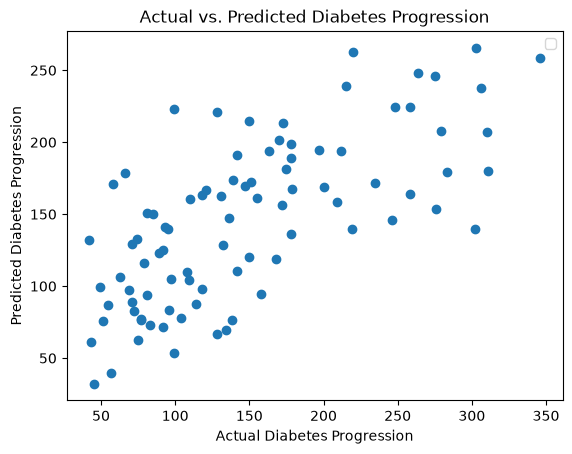

In [5]:
# TODO: Visualize the model's performance with the scatter plot
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Diabetes Progression")
plt.ylabel("Predicted Diabetes Progression")
plt.title("Actual vs. Predicted Diabetes Progression")
plt.legend()
plt.show()

Weights: [  29.85512168 -201.14964437  472.15676438  349.71254531 -911.30796484
  547.37932569   75.69311824  150.58294834  781.53812036   89.19671796]
Bias: 151.56952574876945
Most important parameter: s1 Weight: -911.3079648387502
Least important parameter: age Weight: 29.855121681967034


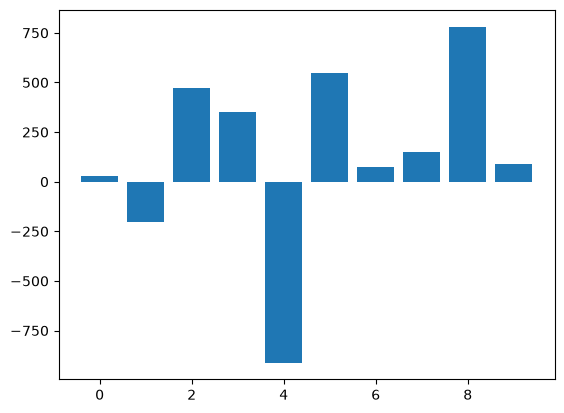

In [6]:
# Separate and print the model weight parameters
# weights (coefficients)
weights = weights_w_bias[:-1]
# bias(intercept)
bias = weights_w_bias[-1]
print("Weights:", weights)
print("Bias:", bias)

# TODO: Plot a bar chart to visualize the parameters:
# Each parameter should be a separate bar, with height equal to its weight
plt.bar(np.arange(10), weights)

# TODO: Show the most and least important parameters
most_import = np.argmax(np.abs(weights))
least_import = np.argmin(np.abs(weights))

print("Most important parameter:", data.feature_names[most_import],
      "Weight:", weights[most_import])
print("Least important parameter:", data.feature_names[least_import],
      "Weight:", weights[least_import])

## Gradient Descent Approach

For this part, you will use a gradient descent approach to implement a linear regression model for the same diabetes dataset. Please refer to the course slides about the gradient calculation and update.

In [7]:
# TODO: Determine learning rate, and training epochs
lr = 0.01          # Try options from 0.1 to 1e-4
num_steps = 13   # Try options from 5 to 20

# TODO: Initialize model parameters
weights = np.zeros(10)
bias = 0

In [8]:
# Model training
for step in range(num_steps):
  # TODO: Compute gradients on weights and bias
  grad_weights = (2/ X_train.shape[0]) * X_train.T @ ((X_train @ weights+ bias) - y_train)
  grad_bias = (2/ X_train.shape[0]) * np.sum((X_train @ weights+ bias) - y_train)

  # TODO: Apply gradient descent to the weights using learning rate
  weights = weights - (lr * grad_weights)
  bias = bias - (lr * grad_bias)

  # TODO: Calculate Mean Squared Error during training
  mse = mean_squared_error(y_train, X_train @ weights + bias)
  print("Training error:", mse)

Training error: 28399.14667604873
Training error: 27508.27483321402
Training error: 26652.65064703633
Training error: 25830.878300629953
Training error: 25041.617252241856
Training error: 24283.580046325227
Training error: 23555.530211295736
Training error: 22856.280240537908
Training error: 22184.689653364672
Training error: 21539.6631327641
Training error: 20920.14873689237
Training error: 20325.136181392645
Training error: 19753.65518973509


In [9]:
# TODO: Make predictions on the test data
y_pred = X_test @ weights + bias

# TODO: Calculate Mean Squared Error for evaluation
mse = mean_squared_error(y_test, X_test @ weights + bias)

# Print the evaluation metrics
print("Mean Squared Error:", mse)

Mean Squared Error: 18799.111407573775


C:\Users\aptls\AppData\Local\Temp\ipykernel_13088\1424789678.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


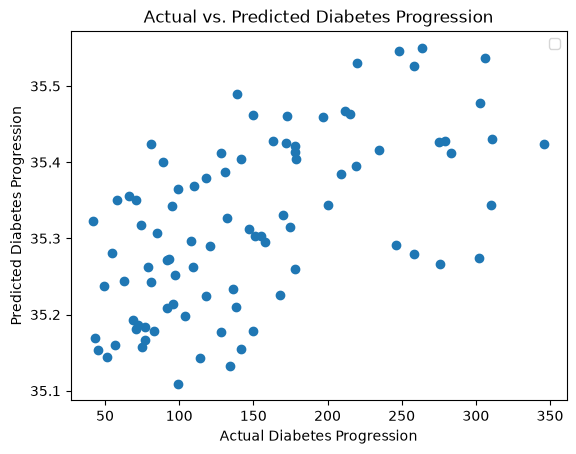

In [10]:
# TODO: Visualize the model's performance with the scatter plot
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Diabetes Progression")
plt.ylabel("Predicted Diabetes Progression")
plt.title("Actual vs. Predicted Diabetes Progression")
plt.legend()
plt.show()

Weights: [ 0.30045593  0.09894015  0.55824144  0.5248049   0.18558212  0.15221432
 -0.41396047  0.44535659  0.55158642  0.40240863]
Bias: 35.331981059003965


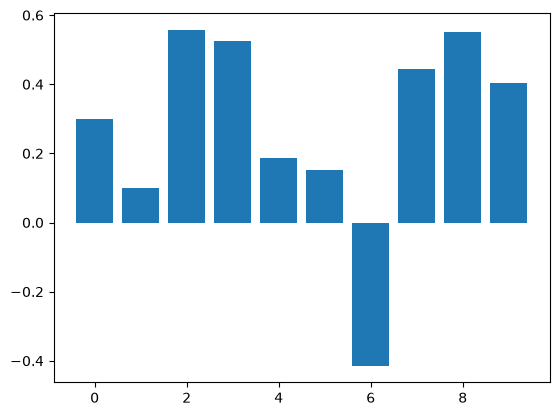

Most important parameter: bmi Weight: 0.5582414417392322
Least important parameter: sex Weight: 0.09894014841376736


In [11]:
# Print the model weight parameters
print("Weights:", weights)
print("Bias:", bias)

# TODO: Plot a bar chart to visualize the parameters
plt.bar(np.arange(10),weights)
plt.show()


# TODO: Show the most and least important parameters
most_import = np.argmax(np.abs(weights))
least_import = np.argmin(np.abs(weights))

print("Most important parameter:", data.feature_names[most_import],
      "Weight:", weights[most_import])
print("Least important parameter:", data.feature_names[least_import],
      "Weight:", weights[least_import])

## Use the California housing dataset housing to train a linear regression model

* Load the dataset from fetch_california_housing
* Train a linear regression model using gradient descent
* Report the model's performance on the test set
* For this dataset, how do the data split (try 20/80 and 50/50 training/test split ratios) and hyper-parameters (learning rate, training epochs) affect the outcome? Show and interpret your results




In [12]:
from sklearn.datasets import fetch_california_housing

# TODO: Load the dataset, train a linear regression model using gradient descent,
# and evaluate the model's performance on the test set

housing = fetch_california_housing()
X = housing.data
y = housing.target
print("features:", X.shape)
print("labels:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.8)
print("training data:", X_train.shape, y_train.shape)
print("test data:",     X_test.shape,  y_test.shape)

weights = np.zeros(8)
bias = 0

lr = 1e-7
num_steps = 20

for step in range(num_steps):
    grad_weights = (2/ X_train.shape[0]) * X_train.T @ ((X_train @ weights+ bias) - y_train)
    grad_bias = (2/ X_train.shape[0]) * np.sum((X_train @ weights+ bias) - y_train)

    weights = weights - (lr * grad_weights)
    bias = bias - (lr * grad_bias)

    mse = mean_squared_error(y_train, X_train @ weights + bias)
    print("Training error:", mse)

y_pred = X_test @ weights + bias

mse = mean_squared_error(y_test, X_test @ weights + bias)

print("20/80 Mean Squared Error:", mse)


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5)

weights = np.zeros(8)
bias = 0

lr = 1e-7
num_steps = 20

for step in range(num_steps):
    grad_weights = (2/ X_train.shape[0]) * X_train.T @ ((X_train @ weights+ bias) - y_train)
    grad_bias = (2/ X_train.shape[0]) * np.sum((X_train @ weights+ bias) - y_train)

    weights = weights - (lr * grad_weights)
    bias = bias - (lr * grad_bias)

    mse = mean_squared_error(y_train, X_train @ weights + bias)
    print("Training error:", mse)

y_pred = X_test @ weights + bias

mse = mean_squared_error(y_test, X_test @ weights + bias)

print("50/50 Mean Squared Error:", mse)



features: (20640, 8)
labels: (20640,)
training data: (4128, 8) (4128,)
test data: (16512, 8) (16512,)
Training error: 3.293260900186015
Training error: 3.001441316347087
Training error: 2.962167322178286
Training error: 2.953927284974621
Training error: 2.9495081166679986
Training error: 2.9455666245372587
Training error: 2.9416920717542325
Training error: 2.9378339785619425
Training error: 2.9339861234250004
Training error: 2.9301477220518577
Training error: 2.926318658173823
Training error: 2.92249889763831
Training error: 2.9186884164291143
Training error: 2.914887191823467
Training error: 2.9110952013055518
Training error: 2.907312422432908
Training error: 2.9035388328199
Training error: 2.899774410135578
Training error: 2.8960191321032887
Training error: 2.8922729765005206
20/80 Mean Squared Error: 2.9696871443240096
Training error: 3.2896450202897216
Training error: 3.0312205155293306
Training error: 2.9985171177090617
Training error: 2.9909629432208944
Training error: 2.98621991

In [13]:
#When I used 0.1 for the learning rate, the training MSE was increased rapidly, indicating that the learning rate was 
#too large and gradient descent diverged. After reducing the learning rate to 1e-7, the training MSE decreased. 
#I also increased the number of steps from 10 to 20. The MSE decreased slightly, but the improvement was small.
#This proves that learning raet has a remarkable effect on the stability of gradient descent, while increasing the number of
#training steps can further reduce the error but may provide smaller improvements as training progresses.
#For the 50/50 and 20/80, as you see above, there is no big difference between them.

# Part 2: Getting Familiar with PyTorch

In this section, you will learn to use essential PyTorch functions.

Make sure you have the required library installed. Run the cell below to check and install them if needed.

In [14]:
# Check and install required libraries
!pip install numpy pandas matplotlib scikit-learn torch --quiet


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\aptls\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [15]:
import torch
torch.manual_seed(0)

## PyTorch Tensor Construction

Let's start with some basic PyTorch tensor operations.

In [17]:
# Task 1: Create tensors with data
t1 = torch.ones(size = (5,3)) # A 2-D tensor with values of all ones and with size of 5x3
t2 = torch.zeros(size = (5,3)) # A 2-D tensor with values of all zeros and with size of 5x3
t3 = torch.eye(3) # A 2-D tensor of an identity matrix with size of 3x3
t4 = torch.rand(size = (3,4)) # A 2-D tensor with random values and size of 3x4
t5 = torch.arange(7) # A 1-D tensor with values from [0, 7) with size of 7.

print(t1)
print(t2)
print(t3)
print(t4)
print(t5)

tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])
tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])
tensor([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.]])
tensor([[0.4963, 0.7682, 0.0885, 0.1320],
        [0.3074, 0.6341, 0.4901, 0.8964],
        [0.4556, 0.6323, 0.3489, 0.4017]])
tensor([0, 1, 2, 3, 4, 5, 6])


In [20]:
import numpy as np

# Task 2: Convert tensors from existing data and convert tensors to numpy arrays
t1 = torch.tensor([1,2,3,4])  # Create a tensor from Python list [1,2,3,4]
t2 = torch.tensor(np.array([1,2,3,4]))  # Create a tensor from numpy array np.array([1,2,3,4])
t3 = t2.clone()  # Clone a tensor from an existing tensor t2
t4 = t3.numpy()  # Convert tensor t3 to a numpy array
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
t5 = t3.to(device) # Move tensor t3 to GPU

print(t1)
print(t2)
print(t3)
print(t4)
print(t5)

tensor([1, 2, 3, 4])
tensor([1, 2, 3, 4])
tensor([1, 2, 3, 4])
[1 2 3 4]
tensor([1, 2, 3, 4])


## Pivoting and Reshaping tensors
In the following section, we cover common methods used to pivot and reshape tensors, namely:
1. Flatten
1. Squeeze
1. Reshape
1. Transpose

In [31]:
t = torch.rand(size=(3,4,5))
print(t)

# Task 3: Pivot and reshape tensors
t1 = t.flatten()  # Flatten tensor t
t2 = t.unsqueeze(0) # Add a new dimension to t at dimension 0
t3 = t.squeeze(0)  # Remove the dimension in t2 with size of 1
t4 = t.reshape(12,5) # Reshape t to size of 12x5
t5 = t.transpose(0,1) # Transpose tensor t

print(t1)
print(t2)
print(t3)
print(t4)
print(t5)

tensor([[[0.1449, 0.6859, 0.9244, 0.5328, 0.1668],
         [0.3209, 0.6092, 0.1188, 0.7484, 0.0461],
         [0.0194, 0.0142, 0.3986, 0.8362, 0.0268],
         [0.9156, 0.3000, 0.6464, 0.5228, 0.0491]],

        [[0.9147, 0.7692, 0.9970, 0.7526, 0.1700],
         [0.9173, 0.5269, 0.7371, 0.0991, 0.3562],
         [0.0091, 0.3053, 0.6079, 0.1074, 0.6594],
         [0.7684, 0.5697, 0.1655, 0.1123, 0.3457]],

        [[0.7195, 0.9932, 0.7875, 0.4437, 0.6753],
         [0.0095, 0.0729, 0.7333, 0.2168, 0.7405],
         [0.1470, 0.2523, 0.0882, 0.7609, 0.4491],
         [0.8848, 0.8094, 0.7767, 0.5161, 0.3454]]])
tensor([0.1449, 0.6859, 0.9244, 0.5328, 0.1668, 0.3209, 0.6092, 0.1188, 0.7484,
        0.0461, 0.0194, 0.0142, 0.3986, 0.8362, 0.0268, 0.9156, 0.3000, 0.6464,
        0.5228, 0.0491, 0.9147, 0.7692, 0.9970, 0.7526, 0.1700, 0.9173, 0.5269,
        0.7371, 0.0991, 0.3562, 0.0091, 0.3053, 0.6079, 0.1074, 0.6594, 0.7684,
        0.5697, 0.1655, 0.1123, 0.3457, 0.7195, 0.9932, 0.7875

## Tensor Stack and Repeat
1. Cat
2. Stack
3. Repeat

In [32]:
tx = torch.rand(size=(3,4))
ty = torch.rand(size=(3,4))

# Task 4: Stack and repeat tensors
t1 = torch.cat([tx,ty], dim = 1) # Concatenate tx and ty at dimension 1
t2 = torch.stack([tx,ty], dim = 0) # Stack tx and ty at dimension 0
t3 = tx.repeat(1,3) # Repeat tx 3 times along dimension 1

print(t1)
print(t2)
print(t3)

tensor([[0.3913, 0.5665, 0.7479, 0.1497, 0.7506, 0.7960, 0.9233, 0.2305],
        [0.9196, 0.4456, 0.0810, 0.2295, 0.6579, 0.7046, 0.3523, 0.6673],
        [0.9424, 0.9573, 0.0369, 0.8526, 0.3561, 0.8091, 0.3613, 0.3136]])
tensor([[[0.3913, 0.5665, 0.7479, 0.1497],
         [0.9196, 0.4456, 0.0810, 0.2295],
         [0.9424, 0.9573, 0.0369, 0.8526]],

        [[0.7506, 0.7960, 0.9233, 0.2305],
         [0.6579, 0.7046, 0.3523, 0.6673],
         [0.3561, 0.8091, 0.3613, 0.3136]]])
tensor([[0.3913, 0.5665, 0.7479, 0.1497, 0.3913, 0.5665, 0.7479, 0.1497, 0.3913,
         0.5665, 0.7479, 0.1497],
        [0.9196, 0.4456, 0.0810, 0.2295, 0.9196, 0.4456, 0.0810, 0.2295, 0.9196,
         0.4456, 0.0810, 0.2295],
        [0.9424, 0.9573, 0.0369, 0.8526, 0.9424, 0.9573, 0.0369, 0.8526, 0.9424,
         0.9573, 0.0369, 0.8526]])


## Mathematical Operations
1. Point-wise/element-wise operations
1. Reduction operations
1. Vector/Matrix operations

In [26]:
tx = torch.rand(size=(3,4))
ty = torch.rand(size=(3,4))
tz = torch.randn(4)

# Task 5: Math operations
t1 = tx * ty # Element-wise multiplication of tx and ty
t2 = torch.matmul(tx,tz) # Matrix multiplication of tx and tz
t3 = ty.sum(axis = 1) # Calculate the sum of ty along dimension 1

print(t1)
print(t2)
print(t3)

tensor([[0.1074, 0.3268, 0.1810, 0.5003],
        [0.6224, 0.1178, 0.0732, 0.2041],
        [0.0040, 0.4615, 0.0685, 0.0441]])
tensor([0.5214, 0.6135, 0.8592])
tensor([2.6480, 2.0224, 2.0754])


## Autograd
(Some of the content is borrowed from the PyTorch website on autograd: https://pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html)
`torch.autograd` is PyTorch’s automatic differentiation engine that computes gradients.

In [28]:
# Task 6.1: Compute gradient for scalar inputs
x = torch.tensor([2.], requires_grad=True)
y = x ** 2


# TODO - compute the gradient
y.backward()

print(x.grad)
print(2*x == x.grad)

# Task 6.2: Compute gradient for vectors
x = torch.tensor([2.,3.], requires_grad = True)
y = x ** 2

# TODO - compute the gradient
y.sum().backward()

print(x.grad)
print(2*x == x.grad)

tensor([4.])
tensor([True])
tensor([4., 6.])
tensor([True, True])


`torch.autograd` tracks operations on all tensors which have their `requires_grad` flag set to `True`.
The output tensor of an operation will require gradients even if only a single input tensor has `requires_grad=True`.

In [30]:
x = torch.rand(5, 5)
y = torch.rand(5, 5)
z = torch.rand((5, 5), requires_grad=True)

a = x + y
b = x + z

# Task 6.3: Check the gradients of a and b
a_grad = a.requires_grad
b_grad = b.requires_grad
print(f"Does `a` require gradients?: {a_grad}")
print(f"Does `b` require gradients?: {b_grad}")

Does `a` require gradients?: False
Does `b` require gradients?: True


## Understand dataset creation

Write down what functions in torch.utils.data can be used to create a dataset from tensors and load each batch of data for training and testing. (reference https://docs.pytorch.org/docs/stable/data.html)

ANSWER

## Understand PyTorch models
Write down what basic torch.nn function can be used for a linear model. (reference https://docs.pytorch.org/docs/stable/nn.html)

ANSWER

##Understand optimizers
Write down at least two optimizers in torch.optim that are useful for updating model weight parameters. (reference https://docs.pytorch.org/docs/main/optim.html)


## Understand loss functions
Write down two loss functions in torch.nn that can be used for binary classification. (reference https://docs.pytorch.org/docs/stable/nn.html)

ANSWER